# Annotation
- The process of labeling groups of cells in data based on known (or sometimes unknown) cellular phenotypes is called `cell_annotation`.
- A cell type is a cellular phenotype that is robust across datasets, identifiable by specific marker genes or proteins, and tied to distinct biological function.

In [1]:
import shutil
import sys
from pathlib import Path

import celltypist
import lamindb as ln
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pandas.core.indexes.base as pandas_indexes_base
import scanpy as sc
import scvi
import seaborn as sns
from cellmapper import CellMapper
from celltypist import models
from scipy.sparse import csr_matrix

ln.connect("theislab/sc-best-practices")

/opt/anaconda3/envs/annotation/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


→ connected lamindb: theislab/sc-best-practices
! connected in read-only mode, please use ln.DB("theislab/sc-best-practices") instead


In [2]:
# set figure parameters
sc.set_figure_params(figsize=(5, 5))

In [3]:
# Loading preprocessed data
af = ln.Artifact.get(key="cellular_structure/s4d8_clustered.h5ad", is_latest=True)
adata = af.load(is_run_input=False)

In [4]:
adata

AnnData object with n_obs × n_vars = 13668 × 20362
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'logit_mt_fraction', 'outlier', 'mt_outlier', 'soupx_groups', 'scDblFinder_score', 'scDblFinder_class', 'size_factors', 'leiden', 'leiden_res0_25', 'leiden_res0_5', 'leiden_res1'
    var: 'gene_ids', 'feature_types', 'genome', 'interval', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_deviant', 'binomial_deviance', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'leiden', 'leiden_res0_25', 'leiden_res0_25_colors', 'leiden_res0_5', 'leiden_res0_5_colors', 'leiden_res1', 'leiden_res1_colors', 'nei

# Manual annotation
- The oldest way to perform cell type annotation is based on a set of marker genes associated with a particular cell type. When no unique markers exist for a specific cell type, a combination of markers may be necessary for proper annotation but that requires prior knowledge and annotation experience.
- Clustering before annotation is helpful as it allows annotating groups of cells. Annotating per-cell can be tedious as well as noisy because single-cell data is sparse and a cell might not have expression of a particular gene while a group of cells can indicate so.
- Two approaches for marker-based gene annotation:
    - Using a table of marker genes for all the cell types and check in which clusters those genes are expressed.
    - To check which genes are highly expressed in the clusters defined by clustering algorithms and then check if they are associated with known cell types or states.

## From markers to cluster annotation

In [5]:
# keys: cell types or populations, values: lists of marker genes
marker_genes = {
    "CD14+ Mono": ["FCN1", "CD14"],
    "CD16+ Mono": ["TCF7L2", "FCGR3A", "LYN"],
    "ID2-hi myeloid prog": [
        "CD14",
        "ID2",
        "VCAN",
        "S100A9",
        "CLEC12A",
        "KLF4",
        "PLAUR",
    ],
    "cDC1": ["CLEC9A", "CADM1"],
    "cDC2": [
        "CST3",
        "COTL1",
        "LYZ",
        "DMXL2",
        "CLEC10A",
        "FCER1A",
    ],  # Note: DMXL2 should be negative
    "Normoblast": ["SLC4A1", "SLC25A37", "HBB", "HBA2", "HBA1", "TFRC"],
    "Erythroblast": ["MKI67", "HBA1", "HBB"],
    "Proerythroblast": [
        "CDK6",
        "SYNGR1",
        "HBM",
        "GYPA",
    ],  # Note HBM and GYPA are negative markers
    "NK": ["GNLY", "NKG7", "CD247", "GRIK4", "FCER1G", "TYROBP", "KLRG1", "FCGR3A"],
    "ILC": ["ID2", "PLCG2", "GNLY", "SYNE1"],
    "Lymph prog": [
        "VPREB1",
        "MME",
        "EBF1",
        "SSBP2",
        "BACH2",
        "CD79B",
        "IGHM",
        "PAX5",
        "PRKCE",
        "DNTT",
        "IGLL1",
    ],
    "Naive CD20+ B": ["MS4A1", "IL4R", "IGHD", "FCRL1", "IGHM"],
    "B1 B": [
        "MS4A1",
        "SSPN",
        "ITGB1",
        "EPHA4",
        "COL4A4",
        "PRDM1",
        "IRF4",
        "CD38",
        "XBP1",
        "PAX5",
        "BCL11A",
        "BLK",
        "IGHD",
        "IGHM",
        "ZNF215",
    ],  # Note IGHD and IGHM are negative markers
    "Transitional B": ["MME", "CD38", "CD24", "ACSM3", "MSI2"],
    "Plasma cells": ["MZB1", "HSP90B1", "FNDC3B", "PRDM1", "IGKC", "JCHAIN"],
    "Plasmablast": ["XBP1", "RF4", "PRDM1", "PAX5"],  # Note PAX5 is a negative marker
    "CD4+ T activated": ["CD4", "IL7R", "TRBC2", "ITGB1"],
    "CD4+ T naive": ["CD4", "IL7R", "TRBC2", "CCR7"],
    "CD8+ T": ["CD8A", "CD8B", "GZMK", "GZMA", "CCL5", "GZMB", "GZMH", "GZMA"],
    "T activation": ["CD69", "CD38"],  # CD69 much better marker!
    "T naive": ["LEF1", "CCR7", "TCF7"],
    "pDC": ["GZMB", "IL3RA", "COBLL1", "TCF4"],
    "G/M prog": ["MPO", "BCL2", "KCNQ5", "CSF3R"],
    "HSC": ["NRIP1", "MECOM", "PROM1", "NKAIN2", "CD34"],
    "MK/E prog": [
        "ZNF385D",
        "ITGA2B",
        "RYR3",
        "PLCB1",
    ],  # Note PLCB1 is a negative marker
}

In [6]:
# Subset to markers that were detected in our data
marker_genes_in_data = {}
for ct, markers in marker_genes.items():
    markers_found = []
    for marker in markers:
        if marker in adata.var.index:
            markers_found.append(marker)
    marker_genes_in_data[ct] = markers_found

In [7]:
adata.X = adata.layers["scran_normalization"]

In [8]:
adata.var["highly_variable"] = adata.var["highly_deviant"]

In [9]:
# Computing PCA using the highly deviant genes
sc.tl.pca(adata, n_comps=50, mask_var="highly_variable")

In [10]:
# Calculating neighboring graphs based on PCs
sc.pp.neighbors(adata)

In [11]:
# Using the neighbor graph to calculate UMAP
sc.tl.umap(adata)

In [12]:
# Example B-cell subtypes we want to visualize the markers for:
B_plasma_cts = [
    "Naive CD20+ B",
    "B1 B",
    "Transitional B",
    "Plasma cells",
    "Plasmablast"
]

NAIVE CD20+ B:


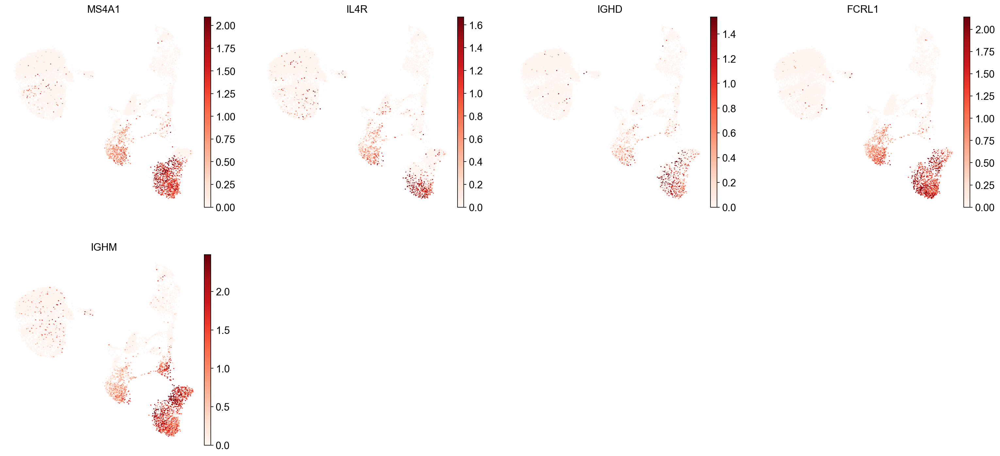





B1 B:


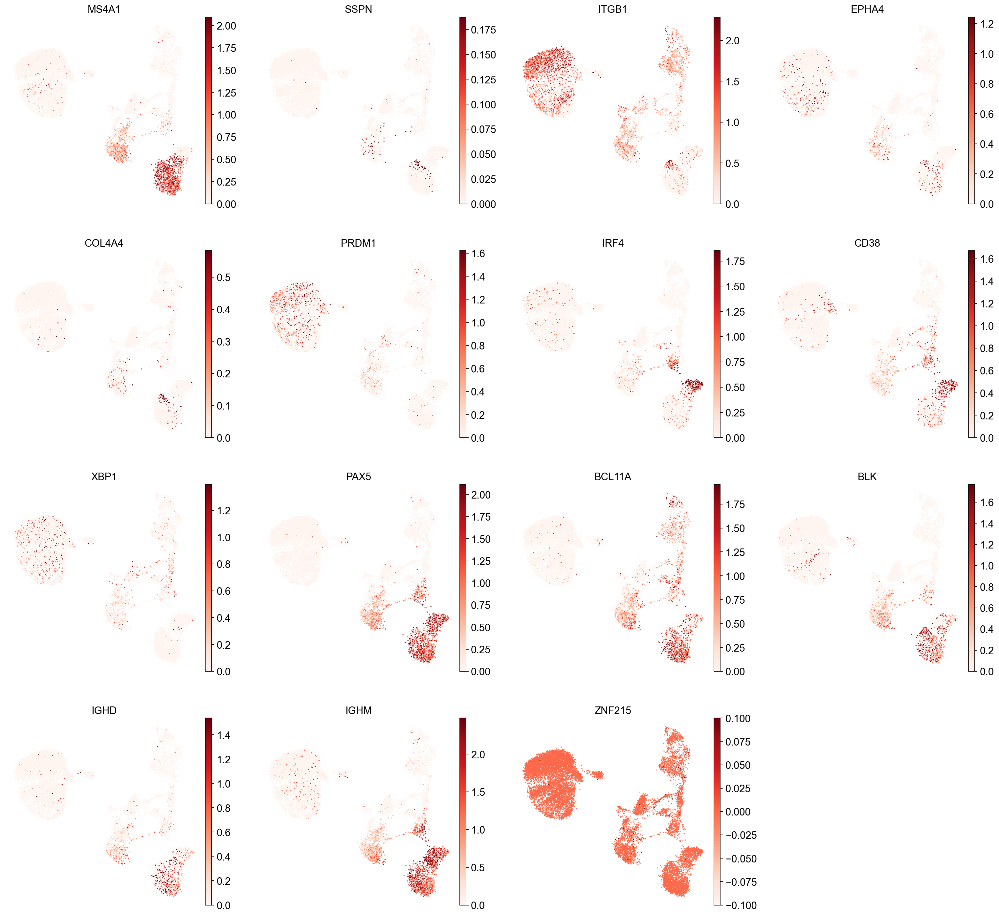





TRANSITIONAL B:


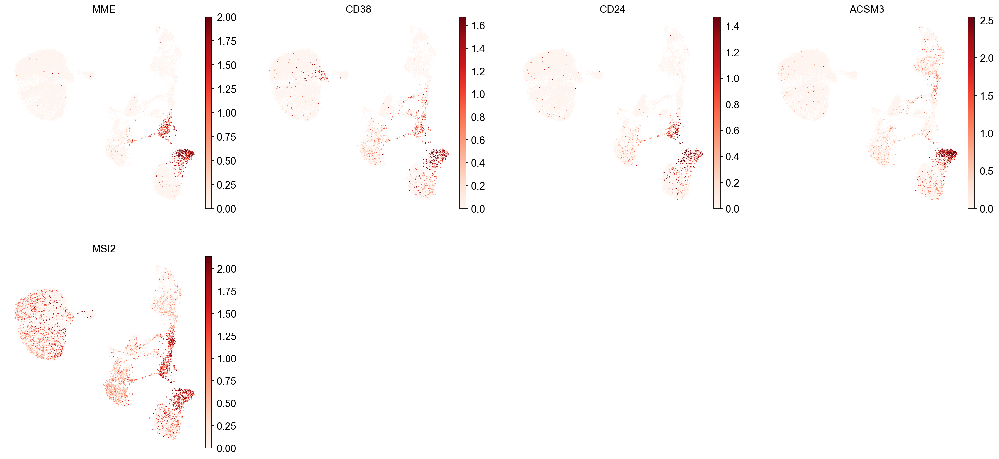





PLASMA CELLS:


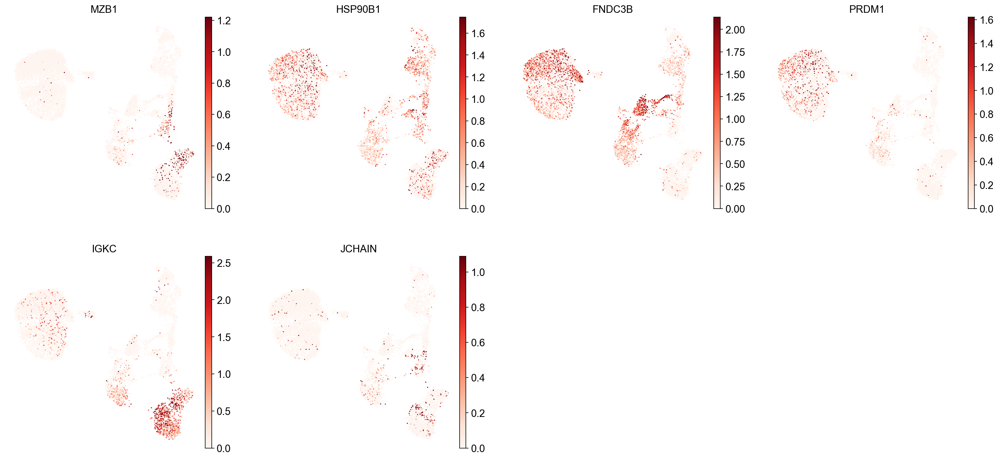





PLASMABLAST:


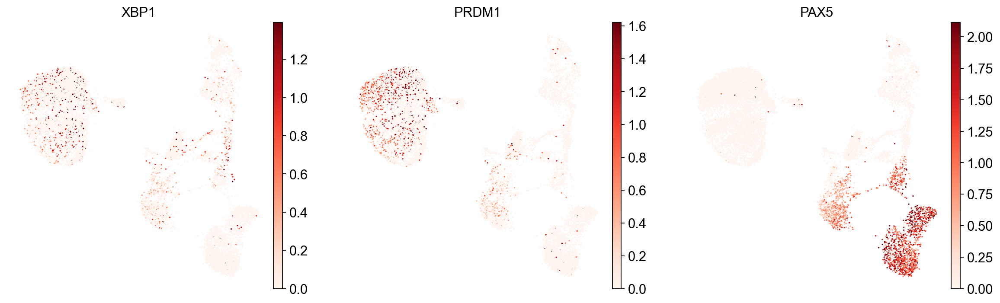

In [13]:
# Plotting one UMAP per marker for each of the B cell subtypes
for ct in B_plasma_cts:
    print(f"{ct.upper()}:") # print cell subtype name
    sc.pl.umap(
        adata,
        color=marker_genes_in_data[ct],
        vmin=0,
        vmax="p99",
        # set vmax to the 99th percentile of the gene count instead of the maximum, to prevent outliers from making expression in other
        # cells invisible. Note that this can cause problems for extremely lowly expressed genes.
        sort_order=False, # Do not plot highest expression on top, to not get a biased view of the mean expression among cells
        frameon=False,
        cmap="Reds"
    )
    print("\n\n\n")

- *Markers for a single cell type are often expressed in different subsets of the data i.e. individual markers are often not uniquely expressed in a single cell type. It is the intersection of the subsets that will tell where our cell type of interest is.*
- The nature of scRNA-seq is such that we sequence only a small subset of the total amount of RNA molecules in the cell, and due to subsampling, we will sometimes not sample transcripts from specific genes in a cell even if they were expressed in that cell. Therefore, we first cluster the data and group them based on overall transcriptomic similarity. We can then annotate those clusters based on their overall marker expression patterns.

In [14]:
# Leiden clustering
sc.tl.leiden(adata, resolution=1, key_added="leiden_1", flavor="igraph", n_iterations=2)

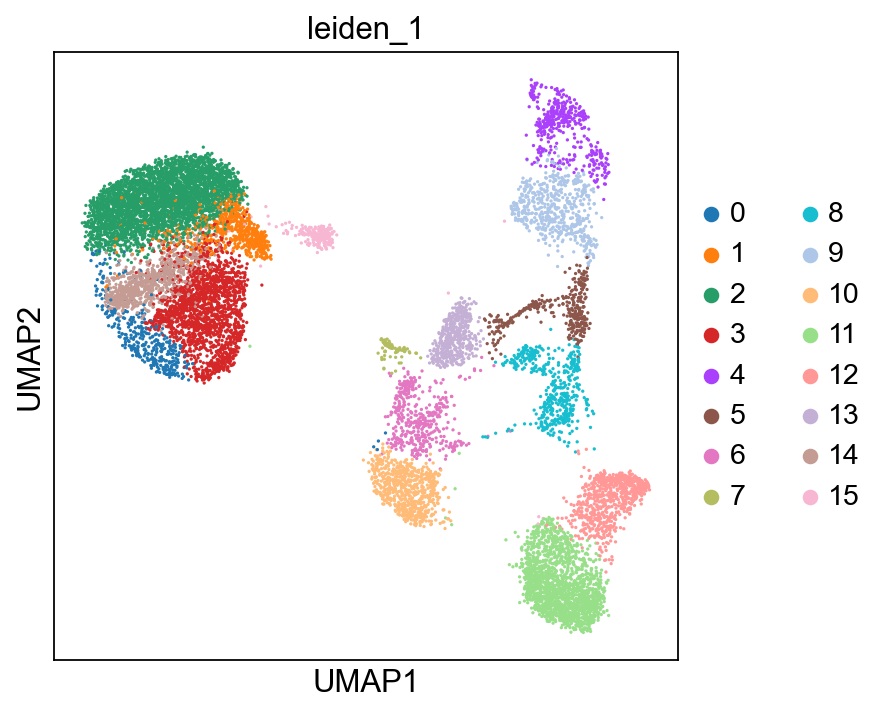

In [15]:
sc.pl.umap(adata, color="leiden_1")

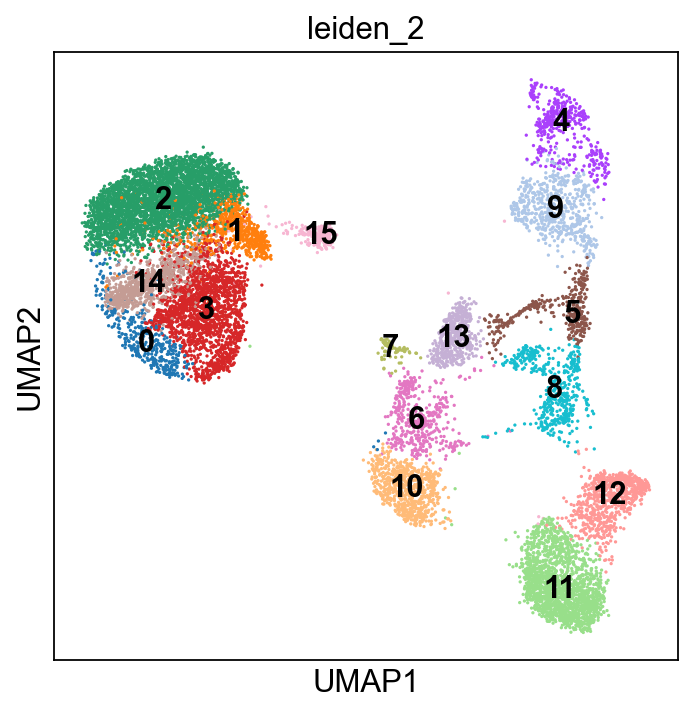

In [16]:
# For the partitioning to be finer, we can change the resolution to a higher level
sc.tl.leiden(adata, resolution=1, key_added="leiden_2", flavor="igraph", n_iterations=2)
sc.pl.umap(adata, color="leiden_2", legend_loc="on data")

### We can see that cluster 11 consistently expresses Naive CD20+ B cell markers while cluster 12 consistently expresses traditional B cell markers

In [17]:
# Visualizing the same using dotplot
B_plasma_markers = {
    ct: [m for m in ct_markers if m in adata.var.index]
    for ct, ct_markers in marker_genes.items()
    if ct in B_plasma_cts
}

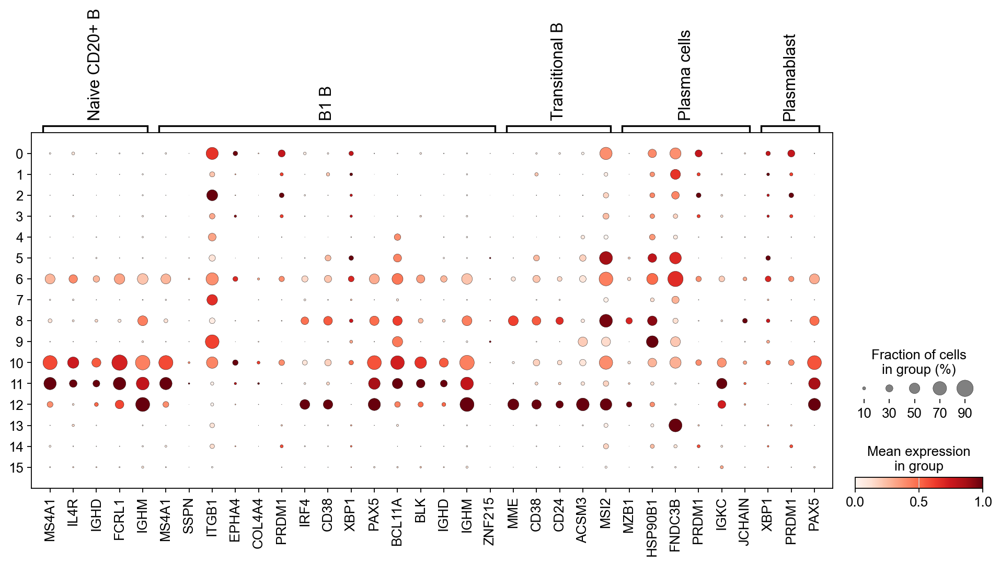

In [18]:
sc.pl.dotplot(
    adata,
    groupby="leiden_1",
    var_names=B_plasma_markers,
    standard_scale="var" # standard scale: normalize each gene to range from 0 to 1
)

In [19]:
cl_annotation = {
    "11": "Naive CD20+ B",
    "12": "Transitional B"
}

From the above UMAP and dotplot, the annotation of B1 B cells is difficult with none of the clusters expressing all the B1 B markers and several clusters expressing some of the markers.

In [20]:
adata.obs["manual_celltype_annotation"] = adata.obs.leiden_1.map(cl_annotation)

... storing 'manual_celltype_annotation' as categorical


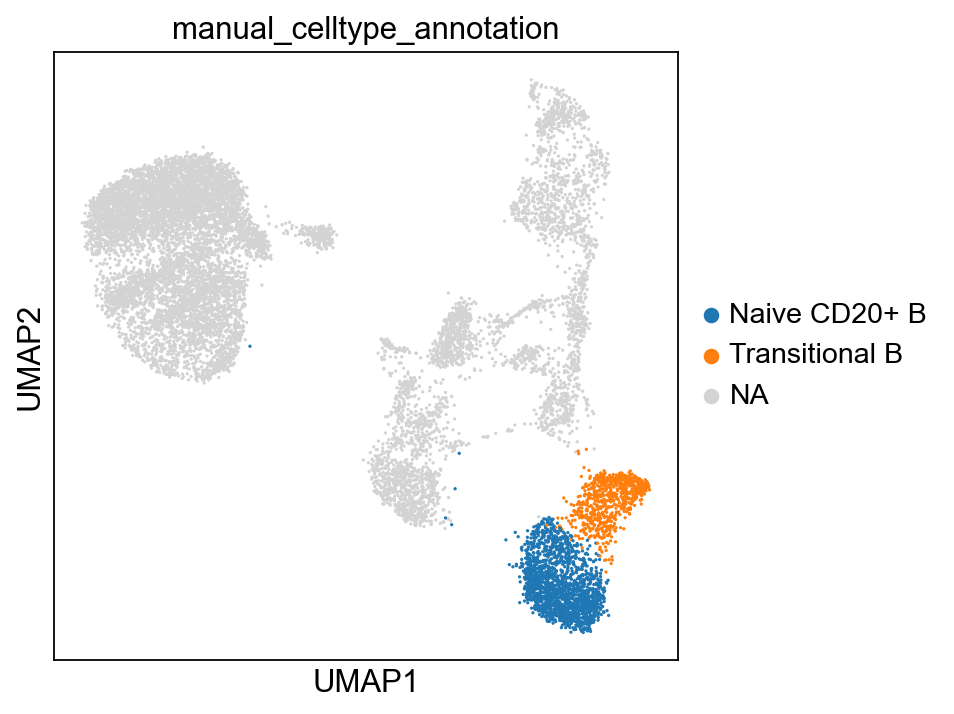

In [21]:
sc.pl.umap(adata, color=["manual_celltype_annotation"])

## From cluster differentially expressed genes to cluster annotation
- Clustering marker genes per cluster and then looking up whether we can link those marker genes to any known biology, such as cell types or states.
- For marker gene calculation of clusters, methods such as Wilcoxon rank-sum test performs best. As the definition of clusters is based on the same data as used for these statistical tests, the p-values of these tests will be inflated.

In [22]:
# Calculating the differentially expressed genes for every cluster, compared to the rest of the cells in our adata
sc.tl.rank_genes_groups(adata, groupby="leiden_1", method="wilcoxon", key_added="dea_leiden_1")

In [23]:
adata

AnnData object with n_obs × n_vars = 13668 × 20362
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'logit_mt_fraction', 'outlier', 'mt_outlier', 'soupx_groups', 'scDblFinder_score', 'scDblFinder_class', 'size_factors', 'leiden', 'leiden_res0_25', 'leiden_res0_5', 'leiden_res1', 'leiden_1', 'leiden_2', 'manual_celltype_annotation'
    var: 'gene_ids', 'feature_types', 'genome', 'interval', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_deviant', 'binomial_deviance', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'leiden', 'leiden_res0_25', 'leiden_res0_25_colors', 'leiden_res0_5', 'leiden_res

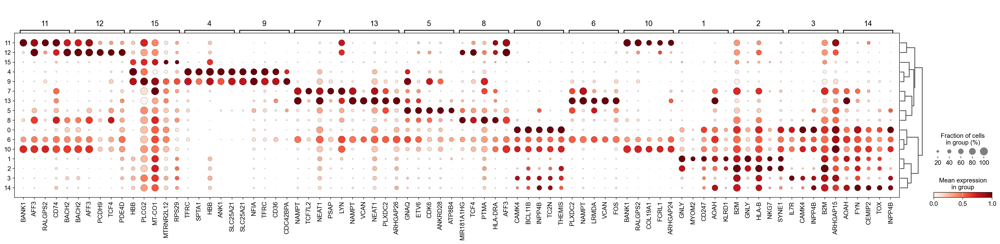

In [24]:
# Visualizing the expression of the top differentially expressed genes per cluster
sc.tl.dendrogram(adata, groupby="leiden_1")
sc.pl.rank_genes_groups_dotplot(adata, groupby="leiden_1", standard_scale="var", n_genes=5, key="dea_leiden_1")

In [25]:
# As there are a lot of differentially expressed genes that are highly expressed in multiple clusters,
# we can filter the differentially expressed genes to select for more cluster-specific differentially expressed genes
sc.tl.filter_rank_genes_groups(
    adata,
    min_in_group_fraction=0.2, # Minimum fraction of cells expressing the gene inside the group
    max_out_group_fraction=0.2, # Maximum fraction of cells expressing the gene outside the group
    key="dea_leiden_1",
    key_added="dea_leiden_1_filtered"
)

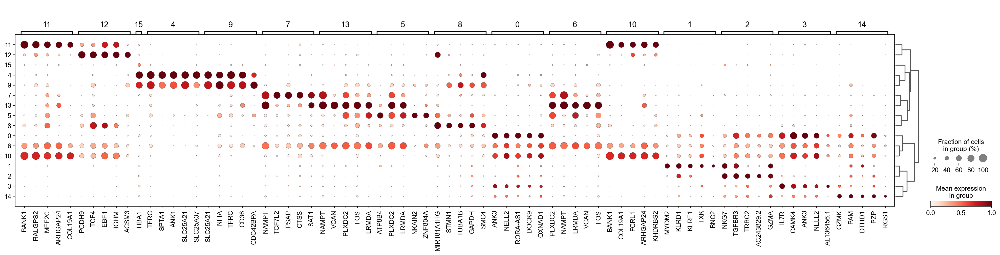

In [26]:
# Visualizing the filtered genes
sc.pl.rank_genes_groups_dotplot(adata, groupby="leiden_1", standard_scale="var", n_genes=5, key="dea_leiden_1_filtered")

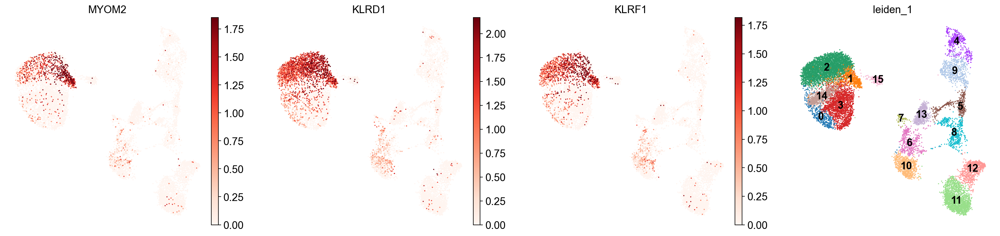

In [27]:
# Looking at cluster 1
sc.pl.umap(
    adata,
    color=["MYOM2", "KLRD1", "KLRF1", "leiden_1"],
    vmax="p99",
    legend_loc="on data",
    frameon=False,
    cmap="Reds",
)

In [28]:
cl_annotation["1"] = "NK cells (?)"

In [29]:
adata.obs["manual_celltype_annotation"] = adata.obs.leiden_1.map(cl_annotation)

**Disadvantages of manual annotation:** Marker-based annotation can be sensitive to cluster resolution we choose, the robustness and uniqueness of the marker sets and the knowledge of the cell types in our data.

This is why automated annotation is more preferrable than manual annotation.

# Automated Annotation
- The quality of automated annotations depend upon:
1. **The type of classifier chosen:** Previous comparisons have shows neural netwokrk-based methods generally does not outperform general-purpose models such as SVM or linear regression models.
2. **The quality of data the classifier was trained on**
3. **The similarity of my data to the data the classifier was trained on:** Classifiers trained on cross-dataset atlases including a diversity of datasets might give more robust and better quality annotations than classifiers trained on a single dataset.

- Advantages of pre-trained classifiers to annotate our data:
1. Fast and easy way to annotate our data using information from high quality annotation.
2. Doesn't rely on partitioning of the data into cluster, as manual annotation does.
3. Helps in harmonizing cell-type definitions across various fields.

- An uncertainty measure is useful for quantifying annotation uncertainty which in turn improves the quality and usability of the method.

## Marker gene-based classifiers
- Such classifiers rely on a predefined set of marker genes to classify cells into cell types based on the expression level of marker genes.
- They might be affected by batch-related differences between the data the model was trained on and the data that needs to be labelled.
- Uses only a small subset of genes detected in the data.
- Advantage: We know on the basis of which genes the classification is done.
- Examples: **Garnett**, **CellAssign**

## Classifiers based on a wider set of genes
- Such classifiers are trained on larger set of genes from previously annotated datasets or atlases.
- Example: **CellTypist**, **Clustifyr**

In [30]:
adata_celltypist = adata.copy()
adata_celltypist.X = adata.layers["counts"].copy() # set adata.X to raw counts

sc.pp.normalize_total(adata_celltypist, target_sum=10**4) # normalize to 10,000 counts per cell
sc.pp.log1p(adata_celltypist) # log-transform
# making .X dense instead of sparse, for compatibility with celltypist
adata_celltypist.X = adata_celltypist.X.toarray()

In [31]:
# Downloading the celltypist models for immune cells
models.download_models(
    force_update=True, 
    model=[
        "Immune_All_Low.pkl", # Immune cell types finer annotation level
        "Immune_All_High.pkl" # Immune cell types coarse annotation level
    ]
)

📜 Retrieving model list from server https://celltypist.cog.sanger.ac.uk/models/models.json
📚 Total models in list: 61
📂 Storing models in /Users/ankitmukherjee/.celltypist/data/models
💾 Total models to download: 2
💾 Downloading model [1/2]: Immune_All_Low.pkl
💾 Downloading model [2/2]: Immune_All_High.pkl


In [32]:
model_low = models.Model.load(model="Immune_All_Low.pkl")
model_high = models.Model.load(model="Immune_All_High.pkl")

In [33]:
model_high

CellTypist model with 32 cell types and 6639 features
    date: 2022-07-16 08:53:00.959521
    details: immune populations combined from 20 tissues of 18 studies
    source: https://doi.org/10.1126/science.abl5197
    version: v2
    cell types: B cells, B-cell lineage, ..., pDC precursor
    features: A1BG, A2M, ..., ZYX

In [34]:
model_high.cell_types

array(['B cells', 'B-cell lineage', 'Cycling cells', 'DC', 'DC precursor',
       'Double-negative thymocytes', 'Double-positive thymocytes', 'ETP',
       'Early MK', 'Endothelial cells', 'Epithelial cells',
       'Erythrocytes', 'Erythroid', 'Fibroblasts', 'Granulocytes',
       'HSC/MPP', 'ILC', 'ILC precursor', 'MNP', 'Macrophages',
       'Mast cells', 'Megakaryocyte precursor',
       'Megakaryocytes/platelets', 'Mono-mac', 'Monocyte precursor',
       'Monocytes', 'Myelocytes', 'Plasma cells', 'Promyelocytes',
       'T cells', 'pDC', 'pDC precursor'], dtype=object)

In [35]:
model_low.cell_types

array(['Age-associated B cells', 'Alveolar macrophages', 'B cells',
       'CD16+ NK cells', 'CD16- NK cells', 'CD8a/a', 'CD8a/b(entry)',
       'CMP', 'CRTAM+ gamma-delta T cells', 'Classical monocytes',
       'Cycling B cells', 'Cycling DCs', 'Cycling NK cells',
       'Cycling T cells', 'Cycling gamma-delta T cells',
       'Cycling monocytes', 'DC', 'DC precursor', 'DC1', 'DC2', 'DC3',
       'Double-negative thymocytes', 'Double-positive thymocytes', 'ELP',
       'ETP', 'Early MK', 'Early erythroid', 'Early lymphoid/T lymphoid',
       'Endothelial cells', 'Epithelial cells', 'Erythrocytes',
       'Erythrophagocytic macrophages', 'Fibroblasts',
       'Follicular B cells', 'Follicular helper T cells', 'GMP',
       'Germinal center B cells', 'Granulocytes', 'HSC/MPP',
       'Hofbauer cells', 'ILC', 'ILC precursor', 'ILC1', 'ILC2', 'ILC3',
       'Intermediate macrophages', 'Intestinal macrophages',
       'Kidney-resident macrophages', 'Kupffer cells',
       'Large pre-B cell

In [36]:
# Running the coarse model for annotation
predictions_high = celltypist.annotate(
    adata_celltypist, model=model_high, majority_voting=True
)

🔬 Input data has 13668 cells and 20362 genes
🔗 Matching reference genes in the model
🧬 5321 features used for prediction
⚖️ Scaling input data
🖋️ Predicting labels
✅ Prediction done!
👀 Detected a neighborhood graph in the input object, will run over-clustering on the basis of it
⛓️ Over-clustering input data with resolution set to 10
🗳️ Majority voting the predictions
✅ Majority voting done!


In [37]:
# Transforming predictions to adata
predictions_high_adata = predictions_high.to_adata()

In [38]:
predictions_high_adata

AnnData object with n_obs × n_vars = 13668 × 20362
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'logit_mt_fraction', 'outlier', 'mt_outlier', 'soupx_groups', 'scDblFinder_score', 'scDblFinder_class', 'size_factors', 'leiden', 'leiden_res0_25', 'leiden_res0_5', 'leiden_res1', 'leiden_1', 'leiden_2', 'manual_celltype_annotation', 'predicted_labels', 'over_clustering', 'majority_voting', 'conf_score'
    var: 'gene_ids', 'feature_types', 'genome', 'interval', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_deviant', 'binomial_deviance', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'leiden',

In [39]:
adata.obs["celltypist_cell_label_coarse"] = predictions_high_adata.obs.loc[
    adata.obs.index, "majority_voting"
]
adata.obs["celltypist_conf_score_coarse"] = predictions_high_adata.obs.loc[
    adata.obs.index, "conf_score"
]

... storing 'manual_celltype_annotation' as categorical


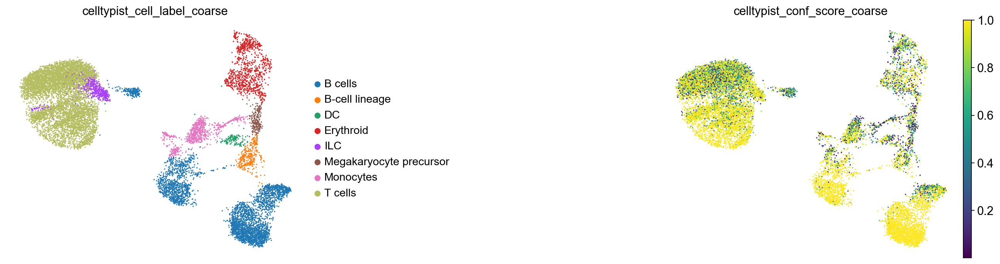

In [43]:
# Plotting the coarser annotations and their confidence
sc.pl.umap(
    adata,
    color=["celltypist_cell_label_coarse", "celltypist_conf_score_coarse"],
    frameon=False,
    sort_order=False,
    wspace=1,
)

In [40]:
# Running the finer annotations model
predictions_low = celltypist.annotate(
    adata_celltypist, model=model_low, majority_voting=True
)

🔬 Input data has 13668 cells and 20362 genes
🔗 Matching reference genes in the model
🧬 5321 features used for prediction
⚖️ Scaling input data
🖋️ Predicting labels
✅ Prediction done!
👀 Detected a neighborhood graph in the input object, will run over-clustering on the basis of it
⛓️ Over-clustering input data with resolution set to 10
🗳️ Majority voting the predictions
✅ Majority voting done!


In [41]:
predictions_low_adata = predictions_low.to_adata()

In [42]:
adata.obs["celltypist_cell_label_fine"] = predictions_low_adata.obs.loc[
    adata.obs.index, "majority_voting"
]
adata.obs["celltypist_conf_score_fine"] = predictions_low_adata.obs.loc[
    adata.obs.index, "conf_score"
]

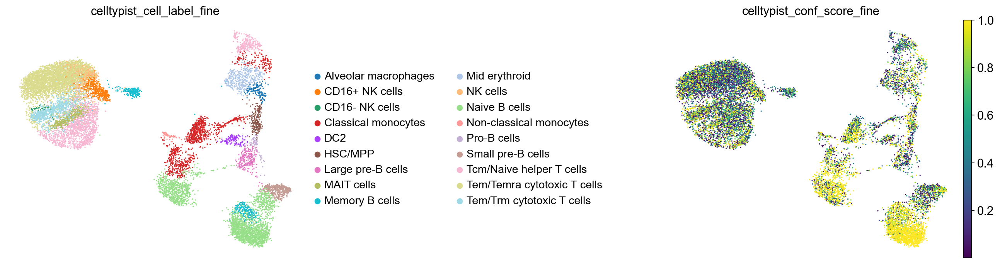

In [44]:
# Plotting the finer annotations and their confidence
sc.pl.umap(
    adata,
    color=["celltypist_cell_label_fine", "celltypist_conf_score_fine"],
    frameon=False,
    sort_order=False,
    wspace=1,
)

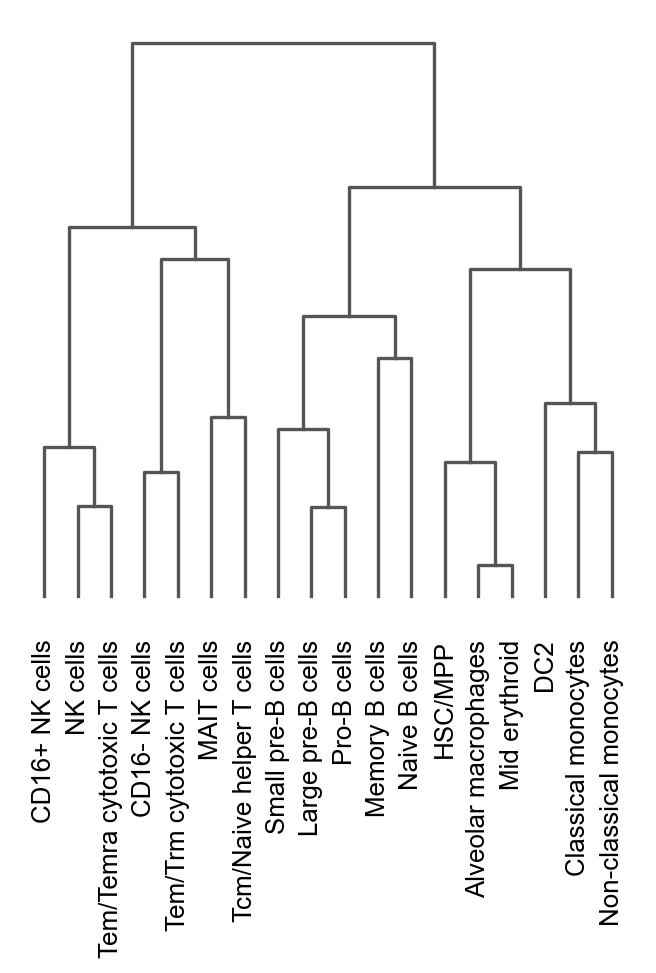

<Axes: >

In [46]:
# A contrary check of annotations
sc.tl.dendrogram(adata, groupby="celltypist_cell_label_fine")
sc.pl.dendrogram(adata, groupby="celltypist_cell_label_fine")

## Large language models and foundation models
- Can propose cell type labels directly from the marker genes of each cluster without requiring a reference dataset.
- Benchmark studies suggest that large LLMs agree well with manual annotations of major cell types, but aggrement is lower for subtypes.
- Cell type annotations differ substantially between models and depends on how the input marker genes were selected.
- Since LLMs rely on previously described knowledge, labels for novel or context-specific cell states should be assessed properly.
- LLM-based labels are best used as a quick first pass that must be checked against marker gene expression and reference annotations.

## Annotation by mapping to a reference
- Based on mapping data to an existing, annotated single-cell reference and then performing label transfer using the resulting joint embedding.
- Example of "query-to-reference mapping" methods: **scArches**, **Symphony**, **Azimuth (Seurat)**
- Identifying unseen cell types is a challenge.
- Integration of the query data with the reference might not always be optimal and batch effects might not be fully removed from the joint query-reference embedding. However, perfect integration is not necessary for annotating our data.

Using **cellmapper**, specifically with scArches as the kernel method for reference-mapping based label transfer.
- It uses variational autoencoder-based model that embeds the reference data in a low-dimensional, batch-corrected space.
- It then slightly extends that model to enable the mapping of an unseen dataset into the same “latent space” (i.e. the low-dimensional embedding).
- This model extension also enables the learning and removal of batch effects present in the mapped dataset.

In [47]:
# scArches requires raw, non-normalized counts
adata_to_map = adata.copy()
for layer in list(adata_to_map.layers.keys()):
    if layer != "counts":
        del adata_to_map.layers[layer]
adata_to_map.X = adata_to_map.layers["counts"]